# 04 — Re-cleaning the Full Set of Study Variables

## Purpose

The purpose of this notebook is to re-clean the World Values Survey (WVS) Wave 7 Singapore data from scratch so that it includes **every variable** we need for the next stage of our study.

Our research question has now been extended to:

**How is parental education associated with traditional gender-role attitudes, and do religiosity, attitudes to science & technology, and political culture moderate this association?**

In `01_clean.ipynb` we only cleaned the gender-role items (Q28–Q31), the science and technology items (Q158–Q163), religiosity (Q164) and parental education (Q277R, Q278R). For the moderation and multivariate models we also need:

- **Political culture:** Q240–Q253
- **Control variables:** respondent's sex (Q260), age (Q262) and own education level (Q275R)

In this notebook we will:

1. Load the raw data and fix the column-alignment problem we found in `01_clean.ipynb`
2. Select the variables and check their coding against the WVS questionnaire
3. Recode missing values and reverse-code items where needed
4. Check Cronbach's alpha before building any composite score
5. Show descriptive statistics for every variable
6. Save the cleaned dataset to `data/processed/` so the later notebooks can load it

We keep the decisions from `01_clean.ipynb` and `02_scale_reliability.ipynb`: all **2,012 Singapore respondents** are kept, the WVS negative codes are treated as missing, Q160–Q162 are reverse-coded, and Q28–Q31 are reverse-coded so that **higher scores mean more traditional gender-role attitudes**. The only change is *how* we read the raw file, which is explained in Section 2.

**Note: This notebook (04) is the expanded and final cleaning pipeline**, and `WVS_Singapore_full_cleaned.csv` is the processed dataset used for **all later analyses (notebooks 05–10)**.

## 1. Setup and Data Loading

This section imports the packages used in this notebook. We use the same libraries as in class: `pandas` and `numpy` for data management and `plotnine` for figures. We also set up the project paths in the same way as `02_scale_reliability.ipynb`, so the notebook works for every team member regardless of where the repository is saved.

In [1]:
from pathlib import Path  # used to build file paths that work on any computer

import pandas as pd  # data management (DataFrames)
import numpy as np  # numerical tools, e.g. np.nan for missing values
from plotnine import *  # ggplot-style figures, as used in class
import warnings  # lets us silence routine warnings
warnings.filterwarnings('ignore')  # hide warnings so the output is easier to read

In [2]:
# Identify the root folder of the GitHub repository.
# This allows the notebook to work whether it is launched from the repository root or from inside the /code folder.
PROJECT_ROOT = Path.cwd()  # start from the folder the notebook is running in

if PROJECT_ROOT.name == "code":  # if we are inside the /code folder...
    PROJECT_ROOT = PROJECT_ROOT.parent  # ...move up one level to the repository root

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "WVS_Wave_7_Singapore_Csv_v5.1.csv"  # raw WVS file (read only, never changed)
OLD_CLEAN_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_cleaned.csv"  # the cleaned file made by 01_clean.ipynb
NEW_CLEAN_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_full_cleaned.csv"  # where this notebook saves its output

OUTPUT_FIGURES = PROJECT_ROOT / "output" / "figures"  # folder for saved figures
OUTPUT_TABLES = PROJECT_ROOT / "output" / "tables"  # folder for saved tables
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)  # create the figures folder if it does not exist yet
OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)  # create the tables folder if it does not exist yet

## 2. Importing the Raw Data and Fixing the Column Alignment

In `01_clean.ipynb` we found that every column in the raw file appeared to be shifted by one position. For example, the column labelled "Q27" actually contained the answers to Q28, so we had to map each variable to its neighbouring column by hand.

When we looked at the raw file more closely, we found the reason: every data row ends with an extra semicolon, so each row has **388** fields while the header only has **387** names. When this happens, pandas automatically uses the first field as the row index, which pushes every value one column to the left.

Instead of mapping each variable by hand, we can fix all columns at once by telling pandas **not** to use the first column as an index (`index_col=False`). Below we check that this gives us the expected number of columns, and that the values are identical to the cleaned file created in `01_clean.ipynb`.

In [3]:
df_raw = pd.read_csv(RAW_PATH, sep=";", index_col=False)  # read the raw file; index_col=False stops the one-column shift

print(f"Number of respondents: {df_raw.shape[0]}")  # number of rows (respondents)
print(f"Number of variables: {df_raw.shape[1]}")  # number of columns (variables)
df_raw[["version", "doi", "A_YEAR", "B_COUNTRY_ALPHA"]].head()  # the first columns should now hold their own values

Number of respondents: 2012
Number of variables: 387


,version,doi,A_YEAR,B_COUNTRY_ALPHA
0,6-0-0 (2024-04-15),doi.org/10.14281/18241.20,2020.0,SGP
1,6-0-0 (2024-04-15),doi.org/10.14281/18241.20,2020.0,SGP
2,6-0-0 (2024-04-15),doi.org/10.14281/18241.20,2020.0,SGP
3,6-0-0 (2024-04-15),doi.org/10.14281/18241.20,2020.0,SGP
4,6-0-0 (2024-04-15),doi.org/10.14281/18241.20,2020.0,SGP


In [4]:
df_old = pd.read_csv(OLD_CLEAN_PATH)  # load the cleaned file from 01_clean.ipynb for comparison

check = df_raw[df_old.columns].copy()  # take the same 15 variables from the newly read raw data
check = check.mask(check < 0)  # recode negative WVS codes as missing, as 01_clean.ipynb did
for col in ["Q160", "Q161", "Q162"]:  # 01_clean.ipynb reverse-coded these three items in place
    check[col] = 11 - check[col]  # apply the same reverse coding

same_values = check.reset_index(drop=True).equals(df_old)  # True if every value (including missing ones) matches
print(f"Values identical to WVS_Singapore_cleaned.csv: {same_values}")  # print the result of the check

Values identical to WVS_Singapore_cleaned.csv: True


### Interpretation

The dataset now has **2,012 respondents and 387 variables**, which matches the number of column names in the file. The first columns also contain the values we expect: `version` holds the dataset version, `doi` holds the DOI, `A_YEAR` holds the survey year (2020) and `B_COUNTRY_ALPHA` holds "SGP". Before the fix, each of these columns held the value of the column to its right.

The check also confirms that, after applying the same missing-value recoding and reverse coding as `01_clean.ipynb`, our 15 variables are **identical** to `WVS_Singapore_cleaned.csv`. This means:

- the manual mapping in `01_clean.ipynb` was correct for the variables it used, so the results in `02` and `03` are unaffected;
- reading the file with `index_col=False` lines up **all** 387 columns at once, so we can now use any variable under its real WVS name (e.g. `Q164`, `Q240`, `Q260`) without mapping it by hand.

One small note: in `01_clean.ipynb` the full-ISCED reference columns for mother's and father's education (Q277 and Q278) were mapped to the wrong neighbouring columns (for example, the column used as "Q277" actually held the spouse's country-specific education code). These columns were only kept for reference and were not used in any analysis, so no results are affected. In this notebook, Q277 and Q278 are the correct ISCED variables.

## 3. Variable Selection

We now select every variable needed for the extended research question. Each variable was checked against the WVS Wave 7 Master Questionnaire.

| Role | Variables | Question wording (short) | Original coding |
|---|---|---|---|
| Outcome | Q28–Q31 | Gender-role statements (mother working, political leaders, university, business executives) | 1 = Strongly agree … 4 = Strongly disagree |
| Parental education | Q277R, Q278R | Mother's / father's highest education, grouped | 1 = Lower, 2 = Middle, 3 = Higher |
| Parental education (reference only) | Q277, Q278 | Mother's / father's highest education, full ISCED scale | 0 = No education … 8 = Doctoral |
| Moderator 1: Religiosity | Q164 | How important is God in your life | 1 = Not at all … 10 = Very important |
| Moderator 2: Science & technology | Q158–Q163 | Six statements about science and technology | 1 = Completely disagree … 10 = Completely agree (Q163: 1 = A lot worse off … 10 = A lot better off) |
| Moderator 3: Political culture | Q240 | Left–right self-placement | 1 = Left … 10 = Right |
| | Q241–Q249 | How essential each item is as a characteristic of democracy | 1 = Not essential … 10 = Essential; 0 = "It is against democracy" |
| | Q250 | Importance of living in a democracy | 1 = Not at all … 10 = Absolutely important |
| | Q251 | How democratically the country is governed | 1 = Not at all … 10 = Completely democratic |
| | Q252 | Satisfaction with the political system | 1 = Not satisfied at all … 10 = Completely satisfied |
| | Q253 | Respect for individual human rights | 1 = A great deal … 4 = None at all |
| Controls | Q260 | Respondent's sex | 1 = Male, 2 = Female |
| | Q262 | Respondent's age | Age in years |
| | Q275R | Respondent's own education, grouped | 1 = Lower, 2 = Middle, 3 = Higher |

In [5]:
gender_items = ["Q28", "Q29", "Q30", "Q31"]  # traditional gender-role attitude items (outcome)
parent_edu = ["Q277R", "Q278R"]  # grouped mother's and father's education (main predictors)
parent_edu_isced = ["Q277", "Q278"]  # full ISCED 0-8 versions, kept for reference only
religiosity = ["Q164"]  # importance of God (moderator 1)
science_items = ["Q158", "Q159", "Q160", "Q161", "Q162", "Q163"]  # science & technology items (moderator 2)
democracy_items = [f"Q{i}" for i in range(241, 250)]  # Q241-Q249: essential characteristics of democracy
political_items = ["Q240"] + democracy_items + ["Q250", "Q251", "Q252", "Q253"]  # all political culture items (moderator 3)
controls = ["Q260", "Q262", "Q275R"]  # sex, age and own education (control variables)

variables = gender_items + parent_edu + parent_edu_isced + religiosity + science_items + political_items + controls  # full list
df = df_raw[variables].copy()  # keep only these variables in a new DataFrame

print(f"Number of selected variables: {df.shape[1]}")  # confirm how many variables were selected

Number of selected variables: 32


## 4. Checking the Raw Coding

Before recoding anything, we check which values appear in each variable. This allows us to identify the missing-value codes and any unexpected values.

According to the WVS questionnaire, the missing-value codes are:

- **−1** = Don't know
- **−2** = No answer / refused
- **−3** = Not applicable (e.g. no mother or father)
- **−5** = Missing for other reasons

For Q241–Q249 there is also a special code, **0 = "It is against democracy"**, which interviewers only recorded if the respondent said it spontaneously (it was not read out as an option).

In [6]:
code_check = pd.DataFrame({  # build a summary table with one row per variable
    "Minimum valid value": df.where(df >= 0).min(),  # smallest non-negative value
    "Maximum valid value": df.where(df >= 0).max(),  # largest non-negative value
    "-1 Don't know": (df == -1).sum(),  # number of "don't know" answers
    "-2 No answer": (df == -2).sum(),  # number of "no answer" answers
    "-3 Not applicable": (df == -3).sum(),  # number of "not applicable" answers
    "-5 Other missing": (df == -5).sum(),  # number of other missing answers
    "0 (Q241-Q249 only)": (df[democracy_items] == 0).sum(),  # number of spontaneous "against democracy" answers
})

code_check["0 (Q241-Q249 only)"] = code_check["0 (Q241-Q249 only)"].fillna(0).astype(int)  # show 0 rather than blank for other items
code_check  # display the table

,Minimum valid value,Maximum valid value,-1 Don't know,-2 No answer,-3 Not applicable,-5 Other missing,0 (Q241-Q249 only)
Q158,1.0,10.0,0,5,0,0,0
Q159,1.0,10.0,0,5,0,0,0
Q160,1.0,10.0,0,19,0,0,0
Q161,1.0,10.0,0,23,0,0,0
Q162,1.0,10.0,0,4,0,0,0
Q163,1.0,10.0,0,9,0,0,0
Q164,1.0,10.0,0,11,0,0,0
Q240,1.0,10.0,248,19,0,0,0
Q241,0.0,10.0,85,8,0,0,1
Q242,0.0,10.0,107,15,0,0,4


### Interpretation

The table shows that every variable only contains the values we expect from the questionnaire, plus the WVS missing-value codes:

- **Gender-role items (Q28–Q31)** range from 1 to 4, and **all 1–10 items** range from 1 to 10. Q253 ranges from 1 to 4, sex (Q260) is 1 or 2, age (Q262) ranges from **21 to 91**, and the grouped education variables (Q275R, Q277R, Q278R) range from 1 to 3.
- **Missing codes:** most items only have a small number of "no answer" (−2) codes. The political culture items have many more **"don't know" (−1)** answers. Q240 (left–right self-placement) stands out with **248 "don't know" answers**, which suggests that many Singaporean respondents are not used to describing their views in left–right terms.
- **Parental education:** Q277R has 116 "don't know", 9 "no answer" and 1 "other missing" code; Q278R has 174 "don't know", 10 "no answer" and 1 "not applicable". Respondents are less able to report their father's education than their mother's.
- **Code 0 ("It is against democracy")** only appears in Q241–Q249 and is very rare: **1** (Q241), **4** (Q242), **1** (Q243), **0** (Q244), **5** (Q245), **3** (Q246), **1** (Q247), **3** (Q248) and **6** (Q249) respondents.

There are no unexpected values, so the only recoding needed is for the missing-value codes and the 0 code (Section 5).

### 4.1 Confirming the Grouped Parental Education Coding

The WVS questionnaire only lists the full ISCED scale (0–8) for Q277 and Q278. To confirm how the grouped versions Q277R and Q278R were created, we cross-tabulate each grouped variable against its original ISCED version (valid answers only).

In [7]:
valid_edu = df[parent_edu + parent_edu_isced].where(df[parent_edu + parent_edu_isced] >= 0)  # ignore missing codes for this check

print("Mother: ISCED level (rows) by grouped level Q277R (columns)")  # label for the first table
print(pd.crosstab(valid_edu["Q277"], valid_edu["Q277R"]))  # cross-tabulate mother's original and grouped education
print("\nFather: ISCED level (rows) by grouped level Q278R (columns)")  # label for the second table
print(pd.crosstab(valid_edu["Q278"], valid_edu["Q278R"]))  # cross-tabulate father's original and grouped education

Mother: ISCED level (rows) by grouped level Q277R (columns)
Q277R  1.0  2.0  3.0
Q277                
0.0    949    0    0
1.0    186    0    0
2.0    167    0    0
3.0      0  299    0
4.0      0  108    0
5.0      0    0   79
6.0      0    0   78
7.0      0    0   18
8.0      0    0    2

Father: ISCED level (rows) by grouped level Q278R (columns)
Q278R  1.0  2.0  3.0
Q278                
0.0    744    0    0
1.0    181    0    0
2.0    181    0    0
3.0      0  305    0
4.0      0  158    0
5.0      0    0   88
6.0      0    0  132
7.0      0    0   31
8.0      0    0    7


### Interpretation

The cross-tables confirm exactly how the grouped education variables were built, for both mothers and fathers:

| Grouped level | ISCED levels included | Meaning |
|---|---|---|
| **1 = Lower** | 0, 1, 2 | No education, primary or lower secondary |
| **2 = Middle** | 3, 4 | Upper secondary or post-secondary non-tertiary |
| **3 = Higher** | 5, 6, 7, 8 | Short-cycle tertiary, bachelor's, master's or doctoral |

Every ISCED level falls into exactly one group, so no respondent was placed in the wrong category. We will use **Q277R (mother) and Q278R (father)** as our parental education measures, as in `03_correlations.ipynb`. The grouping does lose some detail. For example, a mother with no education and a mother with lower secondary education are both coded "Lower".

The table also shows how many parents had little formal education: **949 mothers and 744 fathers** had ISCED level 0 (no education or early-childhood education only). This reflects the fact that many respondents' parents grew up before Singapore's education system expanded.

## 5. Data Recoding and Transformation

### 5.1 Recode WVS Missing-Value Codes

All negative codes are recoded as missing (`NaN`), as in `01_clean.ipynb`.

For Q241–Q249, we also recode **0 ("It is against democracy")** as missing. Our reasons are:

- It is **not a point on the 1–10 scale**. A respondent who says "it is against democracy" is giving a different kind of answer from someone who says "not an essential characteristic" (1), so placing 0 below 1 would treat a qualitatively different answer as if it were simply "a bit less essential".
- It was only recorded when respondents said it **spontaneously**, so other respondents who held the same view may have chosen 1 instead. The code is therefore not measured consistently across respondents.
- It is **very rare** (between 0 and 6 respondents per item, see Section 4), so treating it as missing loses very little information.

In `07_pca.ipynb` we will check whether recoding 0 as 1 instead would change the political culture indices.

In [8]:
df_clean = df.mask(df < 0)  # replace every negative WVS code with NaN (missing)
df_clean[democracy_items] = df_clean[democracy_items].mask(df_clean[democracy_items] == 0)  # treat 0 = "against democracy" as missing

missing_table = pd.DataFrame({  # summarise missing values after recoding
    "Missing (n)": df_clean.isna().sum(),  # number of missing values per variable
    "Missing (%)": (df_clean.isna().mean() * 100).round(1),  # percentage of the full sample that is missing
})
missing_table  # display the table

,Missing (n),Missing (%)
Q28,8,0.4
Q29,24,1.2
Q30,7,0.3
Q31,13,0.6
Q277R,126,6.3
Q278R,185,9.2
Q277,126,6.3
Q278,185,9.2
Q164,11,0.5
Q158,5,0.2


### Interpretation

After recoding, the amount of missing data differs a lot between variables:

- **Low (under 2%):** the gender-role items, religiosity (Q164), all science items, Q250 and Q252. Sex and age have **no missing values**, and own education has only 4.
- **Moderate (2–10%):** mother's education (**6.3%**), father's education (**9.2%**) and most of the democracy items (3–6%).
- **High:** left–right self-placement (Q240) is missing for **13.3%** of respondents.

This matters for the later notebooks. Because regression models only use respondents with complete data on every variable in the model, adding Q240 or the parental education variables will reduce the sample size noticeably. In `06_multivariate_models.ipynb` we will run all models on the **same set of respondents**, so that differences between models are not caused by different samples.

### 5.2 Reverse-Code the Gender-Role Items (Q28–Q31)

In the original coding, **1 = Strongly agree** and **4 = Strongly disagree**. Since agreeing with each statement reflects a more traditional view, a *lower* raw score currently means *more* traditional attitudes.

To stay consistent with `02_scale_reliability.ipynb`, we reverse-code the items with the formula **reversed score = 5 − original score**, so that:

- **1 = Less traditional gender-role attitudes**
- **4 = More traditional gender-role attitudes**

The reversed items are saved as new columns ending in `_rev`, so the original answers are still available.

In [9]:
gender_rev = [f"{item}_rev" for item in gender_items]  # names for the reverse-coded gender items, e.g. Q28_rev
df_clean[gender_rev] = 5 - df_clean[gender_items]  # reverse-code: 1 becomes 4, 2 becomes 3, and so on (NaN stays NaN)

pd.crosstab(df_clean["Q28"], df_clean["Q28_rev"])  # check: each original value should line up with exactly one reversed value

Q28_rev,1.0,2.0,3.0,4.0
Q28,,,,
1.0,0,0,0,104
2.0,0,0,603,0
3.0,0,1079,0,0
4.0,218,0,0,0


The cross-table confirms that the reverse coding worked as intended: every original answer of 1 (strongly agree) is now 4, 2 is now 3, 3 is now 2, and 4 is now 1. The same formula was applied to Q29–Q31.

### 5.3 Reverse-Code the Negatively Worded Science and Technology Items (Q160–Q162)

Q158, Q159 and Q163 are worded **positively** about science (agreeing = more positive), while Q160, Q161 and Q162 are worded **negatively** (agreeing = more negative):

- Q160: "We depend too much on science and not enough on faith"
- Q161: "One of the bad effects of science is that it breaks down people's ideas of right and wrong"
- Q162: "It is not important for me to know about science in my daily life"

As in `01_clean.ipynb`, we reverse-code these three items with **reversed score = 11 − original score**, so that for all six items **higher scores = more positive attitudes toward science and technology**. This time we save the reversed items as new `_rev` columns instead of overwriting the originals.

In [10]:
science_neg = ["Q160", "Q161", "Q162"]  # the negatively worded science items
science_neg_rev = [f"{item}_rev" for item in science_neg]  # names for their reversed versions
df_clean[science_neg_rev] = 11 - df_clean[science_neg]  # reverse-code on the 1-10 scale: 1 becomes 10, 10 becomes 1

pd.crosstab(df_clean["Q160"], df_clean["Q160_rev"])  # check that each original value lines up with the expected reversed value

Q160_rev,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
Q160,,,,,,,,,,
1.0,0,0,0,0,0,0,0,0,0,108
2.0,0,0,0,0,0,0,0,0,98,0
3.0,0,0,0,0,0,0,0,134,0,0
4.0,0,0,0,0,0,0,117,0,0,0
5.0,0,0,0,0,0,472,0,0,0,0
6.0,0,0,0,0,221,0,0,0,0,0
7.0,0,0,0,321,0,0,0,0,0,0
8.0,0,0,304,0,0,0,0,0,0,0
9.0,0,113,0,0,0,0,0,0,0,0


The cross-table confirms the reverse coding: an original answer of 1 (completely disagree that we depend too much on science) is now 10, and an original 10 is now 1. Q161 and Q162 were reversed in the same way.

### 5.4 Reverse-Code Respect for Human Rights (Q253)

Q253 is coded **1 = A great deal of respect** to **4 = No respect at all**, so a higher raw score means *less* respect. To make it run in the same direction as the other political items (higher = more of the thing being measured), we reverse-code it with **5 − original score**, so that **higher scores = more respect for human rights**.

In [11]:
df_clean["Q253_rev"] = 5 - df_clean["Q253"]  # reverse-code Q253 so that 4 = a great deal of respect and 1 = no respect at all

pd.crosstab(df_clean["Q253"], df_clean["Q253_rev"])  # check that the values were reversed correctly

Q253_rev,1.0,2.0,3.0,4.0
Q253,,,,
1.0,0,0,0,301
2.0,0,0,1426,0
3.0,0,210,0,0
4.0,33,0,0,0


The table confirms that 1 ("a great deal of respect") is now 4 and 4 ("no respect at all") is now 1.

### 5.5 Recode the Control Variables

- **Sex (Q260):** recoded into a 0/1 variable `female` (1 = female, 0 = male), using the same approach as the `sex_woman` variable in class. A 0/1 coding makes the regression coefficient easy to read: it is simply the difference between women and men.
- **Age (Q262):** already in years, so it does not need recoding.
- **Own education (Q275R):** already grouped as 1 = Lower, 2 = Middle, 3 = Higher, in the same way as the parental education variables.

In [12]:
df_clean["female"] = np.where(df_clean["Q260"] == 2, 1, 0)  # 1 if the respondent is female (Q260 = 2), otherwise 0
df_clean.loc[df_clean["Q260"].isna(), "female"] = np.nan  # keep missing sex as missing (there are none, but this keeps it safe)

pd.crosstab(df_clean["Q260"], df_clean["female"])  # check that 1 (male) became 0 and 2 (female) became 1

female,0.0,1.0
Q260,,
1.0,924,0
2.0,0,1088


The table confirms that all male respondents (Q260 = 1) are coded 0 and all female respondents (Q260 = 2) are coded 1.

## 6. Internal Consistency: Cronbach's Alpha

Before combining items into a composite score, we check their internal consistency with Cronbach's alpha. We use the same function as in `02_scale_reliability.ipynb`. As in that notebook, only respondents with valid answers on all items in a set are used.

As a rough guide, α ≥ .70 is usually taken as acceptable, α between .60 and .70 as questionable, and α below .60 as too low to combine the items into one score.

In [13]:
def cronbach_alpha(items):
    # Calculate Cronbach's alpha for a set of questionnaire items (one column per item).
    k = items.shape[1]  # number of items
    item_variances = items.var(axis=0, ddof=1)  # variance of each item
    total_scores = items.sum(axis=1)  # total score for each respondent
    total_variance = total_scores.var(ddof=1)  # variance of the total scores
    return k / (k - 1) * (1 - item_variances.sum() / total_variance)  # Cronbach's alpha formula


def alpha_row(label, cols):
    # Return a one-row summary (label, items, N, alpha) for a set of columns.
    complete = df_clean[cols].dropna()  # keep respondents who answered every item in the set
    return {"Scale": label, "Items": ", ".join(cols), "N (complete cases)": len(complete),
            "Cronbach's alpha": round(cronbach_alpha(complete), 3)}  # put the results in a dictionary

### 6.1 Traditional Gender-Role Attitudes (Q28–Q31)

In [14]:
pd.DataFrame([alpha_row("Traditional gender-role attitudes", gender_rev)])  # alpha for the four reversed gender items

,Scale,Items,N (complete cases),Cronbach's alpha
0,Traditional gender-role attitudes,"Q28_rev, Q29_rev, Q30_rev, Q31_rev",1970,0.767


### Interpretation

The Cronbach's alpha for the four reverse-coded gender-role items is **α = .767** (N = 1,970), the same value we found in `02_scale_reliability.ipynb`. This is above the usual .70 threshold, so the four items show **acceptable internal consistency**, supporting their combination into one composite score (alpha does not by itself establish that the score measures traditional gender-role attitudes).

### 6.2 Science and Technology (Q158–Q163)

We first calculate alpha for all six science items, and then without Q160. Q160 ("we depend too much on science and not enough on faith") mentions faith, so it may partly measure religiosity rather than attitudes toward science, which could blur the line between our two moderators.

In [15]:
science_all = ["Q158", "Q159", "Q160_rev", "Q161_rev", "Q162_rev", "Q163"]  # all six items, all coded so higher = more positive
science_no160 = ["Q158", "Q159", "Q161_rev", "Q162_rev", "Q163"]  # the same set without Q160

pd.DataFrame([
    alpha_row("Science & technology: all six items", science_all),  # alpha with Q160
    alpha_row("Science & technology: without Q160", science_no160),  # alpha without Q160
])

,Scale,Items,N (complete cases),Cronbach's alpha
0,Science & technology: all six items,"Q158, Q159, Q160_rev, Q161_rev, Q162_rev, Q163",1977,0.460
1,Science & technology: without Q160,"Q158, Q159, Q161_rev, Q162_rev, Q163",1984,0.464


### Interpretation

The alpha for all six science and technology items is only **α = .460** (N = 1,977). Removing Q160 barely changes it (**α = .464**, N = 1,984). Both values are well below .60, which means the six items **do not** show enough internal consistency to be treated as a single score. Combining them into one score would mix together answers that do not move together, so we do not build a six-item (or five-item) composite.

Since removing Q160 does not fix the problem, the low alpha is not caused by Q160 alone. The next step looks at the item correlations to find out what is going on.

### 6.3 Why Is Alpha So Low? Looking at the Item Correlations

A low alpha means that the items do not move together. To understand why, we look at the correlations between the six (direction-aligned) science items, and also their correlation with religiosity (Q164) to check how much Q160 overlaps with it.

In [16]:
df_clean[science_all + ["Q164"]].corr().round(2)  # Pearson correlations between the science items and religiosity

,Q158,Q159,Q160_rev,Q161_rev,Q162_rev,Q163,Q164
Q158,1.00,0.70,-0.05,0.04,0.21,0.30,-0.05
Q159,0.70,1.00,-0.03,0.01,0.13,0.33,-0.01
Q160_rev,-0.05,-0.03,1.00,0.54,0.03,-0.15,-0.17
Q161_rev,0.04,0.01,0.54,1.00,0.08,-0.14,-0.18
Q162_rev,0.21,0.13,0.03,0.08,1.00,-0.01,-0.07
Q163,0.30,0.33,-0.15,-0.14,-0.01,1.00,0.11
Q164,-0.05,-0.01,-0.17,-0.18,-0.07,0.11,1.00


### Interpretation

The correlation table shows that the science items split into **two separate groups** rather than one scale:

- **Q158, Q159 and Q163** (science makes life better, creates opportunities, and makes the world better off) correlate positively with each other. Q158 and Q159 are strongly related (**r = .70**), and both correlate moderately with Q163 (**r = .30** and **.33**). We call this group **science optimism**.
- **Q160_rev and Q161_rev** (disagreeing that we rely too much on science rather than faith, and that science breaks down ideas of right and wrong) correlate moderately with each other (**r = .54**), but hardly at all with the optimism items (r between −.15 and .04). This group is about **science and faith/morality**.
- **Q162_rev** ("it is *not* important for me to know about science in daily life", reversed) is barely related to any other item (r between −.01 and .21). It seems to measure something different: personal interest in science rather than a judgement about its effects.

In other words, Singaporean respondents can be optimistic about science's practical benefits and, at the same time, worried about its moral effects. These are two different attitudes, which is why one overall score does not work.

**Overlap between Q160 and religiosity:** Q160_rev correlates **r = −.17** with the importance of God (Q164), so more religious respondents are slightly more likely to agree that we depend too much on science and not enough on faith. However, Q161_rev, which does not mention faith, has almost the same correlation with religiosity (**r = −.18**). So Q160 does **not** overlap with religiosity more than its partner item does, and a correlation of about −.17 is weak. This suggests it is reasonable to keep Q160 in the faith/morality group and treat it as separate from religiosity.

In [17]:
science_optimism = ["Q158", "Q159", "Q163"]  # the three positively worded items
science_faith_morality = ["Q160_rev", "Q161_rev"]  # the two items about faith and morality

pd.DataFrame([
    alpha_row("Science optimism (Q158, Q159, Q163)", science_optimism),  # alpha for the optimism items
    alpha_row("Science and faith/morality, with Q160", science_faith_morality),  # alpha for Q160 and Q161 together
    alpha_row("Negatively worded items, with Q162", science_neg_rev),  # alpha for Q160-Q162 together
])

,Scale,Items,N (complete cases),Cronbach's alpha
0,"Science optimism (Q158, Q159, Q163)","Q158, Q159, Q163",2001,0.698
1,"Science and faith/morality, with Q160","Q160_rev, Q161_rev",1981,0.705
2,"Negatively worded items, with Q162","Q160_rev, Q161_rev, Q162_rev",1981,0.446


### Interpretation

The reliability of the two groups identified above is much better than for the six-item set:

- **Science optimism (Q158, Q159, Q163): α = .698** (N = 2,001). This is right at the .70 threshold, so the three items are acceptable to combine.
- **Science and faith/morality (Q160_rev, Q161_rev): α = .705** (N = 1,981). This is also acceptable. Without Q160 this group would only contain one item (Q161), so we cannot calculate an alpha "without Q160" for it. Since Q160 does not overlap with religiosity more than Q161 does (Section 6.3), we keep it.
- **All three negatively worded items (Q160_rev–Q162_rev): α = .446**. Adding Q162 lowers reliability sharply, which confirms that Q162 does not belong with Q160 and Q161.

Based on these results, we build **two science and technology sub-scales** (science optimism and science and faith/morality) and keep Q162_rev as a separate single item. We will check this two-dimensional structure with PCA in `07_pca.ipynb` before using the sub-scales as moderators.

A reasonable alpha only shows that the items in each sub-scale are answered **consistently**. It does not prove that the labels we give them ("science optimism" and "science and faith/morality") are correct. These labels are our interpretation of the item wording. The same caution applies to the political culture sub-indices built in `07_pca.ipynb`.

One limitation is that the faith/morality sub-scale is based on only two items. Alpha tends to be lower when there are few items, so .705 is a reasonable result, but a two-item scale captures less of the concept than a longer one would.

### 6.4 Political Culture (Q240–Q253)

We do **not** build a single political culture index here. These items cover very different ideas: some describe pro-democratic features (Q243, Q246), some describe authoritarian features (Q242, Q245, Q248), some are economic (Q241, Q244, Q247), and the rest are about left–right ideology and evaluations of democracy in Singapore (Q240, Q250–Q253). There is no reason to expect them to form one scale.

Instead, in `07_pca.ipynb` we build sub-indices from items that belong together **by their content** (for example, the authoritarian items Q242, Q245 and Q248), and use PCA, correlations and Cronbach's alpha only to **check** these groups. We do not choose items just because they raise alpha, since a higher alpha shows consistency, not that an item measures the same concept. Because the groups are built and checked in this same sample, the resulting political indices are **exploratory** measures, not validated scales. To show why one index would not work, we report alpha for Q241–Q248 here.

**Q249 ("women have the same rights as men")** is left out of every political culture index. It asks almost the same thing as our outcome variable (gender equality), so including it would partly mean using gender-role attitudes to predict gender-role attitudes. We keep the cleaned Q249 in the dataset so we can show how strongly it correlates with the outcome in `07_pca.ipynb`.

In [18]:
democracy_no249 = [f"Q{i}" for i in range(241, 249)]  # Q241-Q248, leaving out Q249
pd.DataFrame([alpha_row("Essential characteristics of democracy (Q241-Q248)", democracy_no249)])  # alpha for all eight items

,Scale,Items,N (complete cases),Cronbach's alpha
0,Essential characteristics of democracy (Q241-Q...,"Q241, Q242, Q243, Q244, Q245, Q246, Q247, Q248",1792,0.635


### Interpretation

Cronbach's alpha for the eight democracy items (Q241–Q248) is **α = .635** (N = 1,792). This is in the "questionable" range, and the value can be misleading: as we will see in `07_pca.ipynb`, some items (e.g. free elections, Q243) are *negatively* related to others (e.g. religious authorities interpreting the law, Q242). Alpha assumes all items measure the same thing in the same direction, which is not the case here. This supports our decision **not** to combine all the political culture items into one index at this stage.

## 7. Constructing the Composite Scores

Based on the reliability results above, we build the following composite scores. Each is the **mean** of its items, and, as in `02_scale_reliability.ipynb`, a score is only calculated for respondents who answered **all** items in the set (`skipna=False`).

| Composite | Items | Range | Direction |
|---|---|---|---|
| `traditional_gender_attitudes` | Q28_rev–Q31_rev | 1–4 | Higher = **more traditional** gender-role attitudes |
| `science_optimism` | Q158, Q159, Q163 | 1–10 | Higher = more optimistic about the benefits of science and technology |
| `science_faith_morality` | Q160_rev, Q161_rev | 1–10 | Higher = **less** concerned that science undermines faith and morality |

Q162_rev ("it is not important for me to know about science", reversed) is kept as a single item but not combined with the others. The PCA in `07_pca.ipynb` will check whether the science items really form these two dimensions.

In [19]:
df_clean["traditional_gender_attitudes"] = df_clean[gender_rev].mean(axis=1, skipna=False)  # mean of the four reversed gender items
df_clean["science_optimism"] = df_clean[science_optimism].mean(axis=1, skipna=False)  # mean of Q158, Q159 and Q163
df_clean["science_faith_morality"] = df_clean[science_faith_morality].mean(axis=1, skipna=False)  # mean of Q160_rev and Q161_rev

df_clean[gender_rev + ["traditional_gender_attitudes"]].head()  # check the gender score for the first five respondents

,Q28_rev,Q29_rev,Q30_rev,Q31_rev,traditional_gender_attitudes
0,1.0,4.0,1.0,3.0,2.25
1,3.0,4.0,4.0,4.0,3.75
2,2.0,1.0,1.0,2.0,1.50
3,2.0,1.0,1.0,1.0,1.25
4,4.0,1.0,1.0,1.0,1.75


In [20]:
old_scored = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_scored.csv")  # the scored file from 02_scale_reliability.ipynb
same_score = np.allclose(old_scored["traditional_gender_attitudes"], df_clean["traditional_gender_attitudes"], equal_nan=True)  # compare scores
print(f"Gender-role score identical to 02_scale_reliability.ipynb: {same_score}")  # print the result

Gender-role score identical to 02_scale_reliability.ipynb: True


The first five rows show that each composite score is the average of the four reversed items (for example, 1, 4, 1 and 3 average to 2.25). The check confirms that our `traditional_gender_attitudes` score is **identical** to the one created in `02_scale_reliability.ipynb`, so all results from `03_correlations.ipynb` still apply.

## 8. Descriptive Statistics

We now summarise every variable in the cleaned dataset.

### 8.1 Continuous and Scale Variables

For variables measured on a scale (the composite scores, the 1–10 items, the 1–4 items and age), we report the number of valid responses, the number missing, the mean, standard deviation, median, minimum, maximum, skewness and kurtosis, in the same way as `03_correlations.ipynb`. Strictly speaking, the 1–4 and 1–10 items are ordinal, but treating them as approximately continuous is standard practice for summarising attitude scales.

In [21]:
scale_vars = (["traditional_gender_attitudes"] + gender_rev  # outcome composite and its items
              + ["Q164"]  # religiosity
              + ["science_optimism", "science_faith_morality"] + ["Q158", "Q159", "Q163"] + science_neg_rev  # science composites and items
              + ["Q240"] + democracy_items + ["Q250", "Q251", "Q252", "Q253_rev"]  # political culture items
              + ["Q262"])  # age

descriptives = df_clean[scale_vars].agg(["count", "mean", "std", "median", "min", "max", "skew", "kurt"]).T  # one row per variable
descriptives.insert(1, "missing", df_clean[scale_vars].isna().sum())  # add the number of missing values after the count
descriptives = descriptives.rename(columns={  # give the columns readable names
    "count": "Valid N", "missing": "Missing", "mean": "Mean", "std": "SD", "median": "Median",
    "min": "Min", "max": "Max", "skew": "Skewness", "kurt": "Kurtosis"})
descriptives["Valid N"] = descriptives["Valid N"].astype(int)  # show counts as whole numbers

descriptives.to_csv(OUTPUT_TABLES / "full_cleaned_descriptive_statistics.csv")  # save the table
descriptives.round(2)  # display the table rounded to two decimals

,Valid N,Missing,Mean,SD,Median,Min,Max,Skewness,Kurtosis
traditional_gender_attitudes,1970,42,2.12,0.56,2.00,1.0,4.0,0.10,0.05
Q28_rev,2004,8,2.30,0.73,2.00,1.0,4.0,0.29,-0.07
Q29_rev,1988,24,2.21,0.75,2.00,1.0,4.0,0.35,-0.03
Q30_rev,2005,7,1.91,0.74,2.00,1.0,4.0,0.57,0.21
Q31_rev,1999,13,2.06,0.71,2.00,1.0,4.0,0.31,-0.02
Q164,2001,11,6.73,2.96,7.00,1.0,10.0,-0.51,-0.92
science_optimism,2001,11,7.10,1.56,7.33,1.0,10.0,-0.34,0.01
science_faith_morality,1981,31,5.32,2.00,5.50,1.0,10.0,0.25,-0.18
Q158,2007,5,7.36,1.87,8.00,1.0,10.0,-0.58,0.10
Q159,2007,5,7.30,1.94,8.00,1.0,10.0,-0.60,0.04


### Interpretation

**Outcome: traditional gender-role attitudes.** The composite score has **1,970 valid responses** and a mean of **2.12** (SD = 0.56) on a 1–4 scale, the same as in `03_correlations.ipynb`. The average respondent is closer to the less traditional end of the scale. Of the four items, Q28 (children suffer when a mother works, mean = **2.30**) received the most traditional answers, and Q30 (university is more important for boys, mean = **1.91**) received the least traditional answers.

**Religiosity (Q164).** The mean importance of God is **6.73** (SD = 2.96) on a 1–10 scale, so most respondents see God as fairly important. The large standard deviation and negative skew (−0.51) show that answers are spread widely, with more respondents at the "very important" end. This spread is useful for testing moderation.

**Science and technology.** Respondents are fairly optimistic about science (`science_optimism` mean = **7.10**, SD = 1.56), but more divided on its moral effects (`science_faith_morality` mean = **5.32**, SD = 2.00, close to the middle of the scale). Q162_rev has a mean of **7.19**, so most respondents feel that knowing about science is important in daily life.

**Political culture.**
- Respondents place themselves near the centre on the left–right scale (Q240 mean = **5.08**).
- Free elections (Q243, mean = **8.17**) and women's equal rights (Q249, mean = **8.18**) are seen as the most essential characteristics of democracy, while religious authorities interpreting the law (Q242, mean = **3.27**) and the army taking over (Q245, mean = **3.71**) are seen as the least essential. This is what we would expect if most respondents understand democracy in liberal terms.
- Living in a democracy is seen as very important (Q250 mean = **7.98**), and respondents rate Singapore as fairly democratic (Q251 mean = **6.75**). They are fairly satisfied with the political system (Q252 mean = **6.72**) and think there is fairly much respect for human rights (Q253_rev mean = **3.01** on a 1–4 scale).

**Age (Q262).** The mean age is **47.8** years (SD = 16.2), ranging from 21 to 91.

**Shape of the distributions.** Most skewness values lie between −1 and +1, so most variables are not strongly skewed. The exceptions are Q243 (−1.22) and Q249 (−1.15): most respondents gave these items the highest scores, so there is less variation to work with. Q253_rev has a higher kurtosis (2.01) because most respondents (1,426) chose "fairly much respect", so answers are concentrated in one category.

### 8.2 Categorical Variables

The education variables and sex are categorical, so, as in `03_correlations.ipynb`, we describe them with frequencies and percentages instead of means.

In [22]:
edu_labels = {1.0: "1 Lower", 2.0: "2 Middle", 3.0: "3 Higher"}  # labels for the grouped education levels
categorical = {"Q277R": "Mother's education", "Q278R": "Father's education",  # categorical variables and their names
               "Q275R": "Own education", "female": "Female (1 = female, 0 = male)"}

freq_tables = []  # empty list to collect one table per variable
for col, name in categorical.items():  # loop over each categorical variable
    counts = df_clean[col].map(edu_labels if col != "female" else {0.0: "0 Male", 1.0: "1 Female"})  # attach labels
    counts = counts.fillna("Missing").value_counts().sort_index()  # count each category, including missing values
    table = pd.DataFrame({"Variable": name, "Category": counts.index, "Frequency": counts.values,  # build the table
                          "Percentage of full sample (%)": (counts.values / len(df_clean) * 100).round(1)})
    freq_tables.append(table)  # add it to the list

categorical_table = pd.concat(freq_tables, ignore_index=True)  # stack the four tables into one
categorical_table.to_csv(OUTPUT_TABLES / "full_cleaned_categorical_frequencies.csv", index=False)  # save the table
categorical_table  # display the table

,Variable,Category,Frequency,Percentage of full sample (%)
0,Mother's education,1 Lower,1302,64.7
1,Mother's education,2 Middle,407,20.2
2,Mother's education,3 Higher,177,8.8
3,Mother's education,Missing,126,6.3
4,Father's education,1 Lower,1106,55.0
5,Father's education,2 Middle,463,23.0
6,Father's education,3 Higher,258,12.8
7,Father's education,Missing,185,9.2
8,Own education,1 Lower,373,18.5
9,Own education,2 Middle,613,30.5


### Interpretation

- **Mother's education:** most respondents' mothers had **lower** education (**1,302**, 64.7% of the full sample), 407 (20.2%) had middle education and only 177 (**8.8%**) had higher education. 126 respondents (6.3%) are missing.
- **Father's education:** fathers were somewhat more educated: 1,106 (55.0%) lower, 463 (23.0%) middle and 258 (**12.8%**) higher. 185 (9.2%) are missing.
- **Own education:** respondents are much more educated than their parents: **1,022 (50.8%)** have higher education, compared with fewer than 13% of their parents. This big difference between generations reflects the rapid expansion of education in Singapore. It also means that a respondent's own education and their parents' education are measuring quite different experiences.
- **Sex:** 1,088 respondents (54.1%) are female and 924 (45.9%) are male.

The small number of respondents with highly educated mothers (177) is worth keeping in mind. Results for this group are based on fewer people, so they will be less precise than results for the lower-education group.

### 8.3 Distributions of the Composite Scores

Finally, we plot histograms of the three composite scores to see how they are spread out before we use them in the analyses.

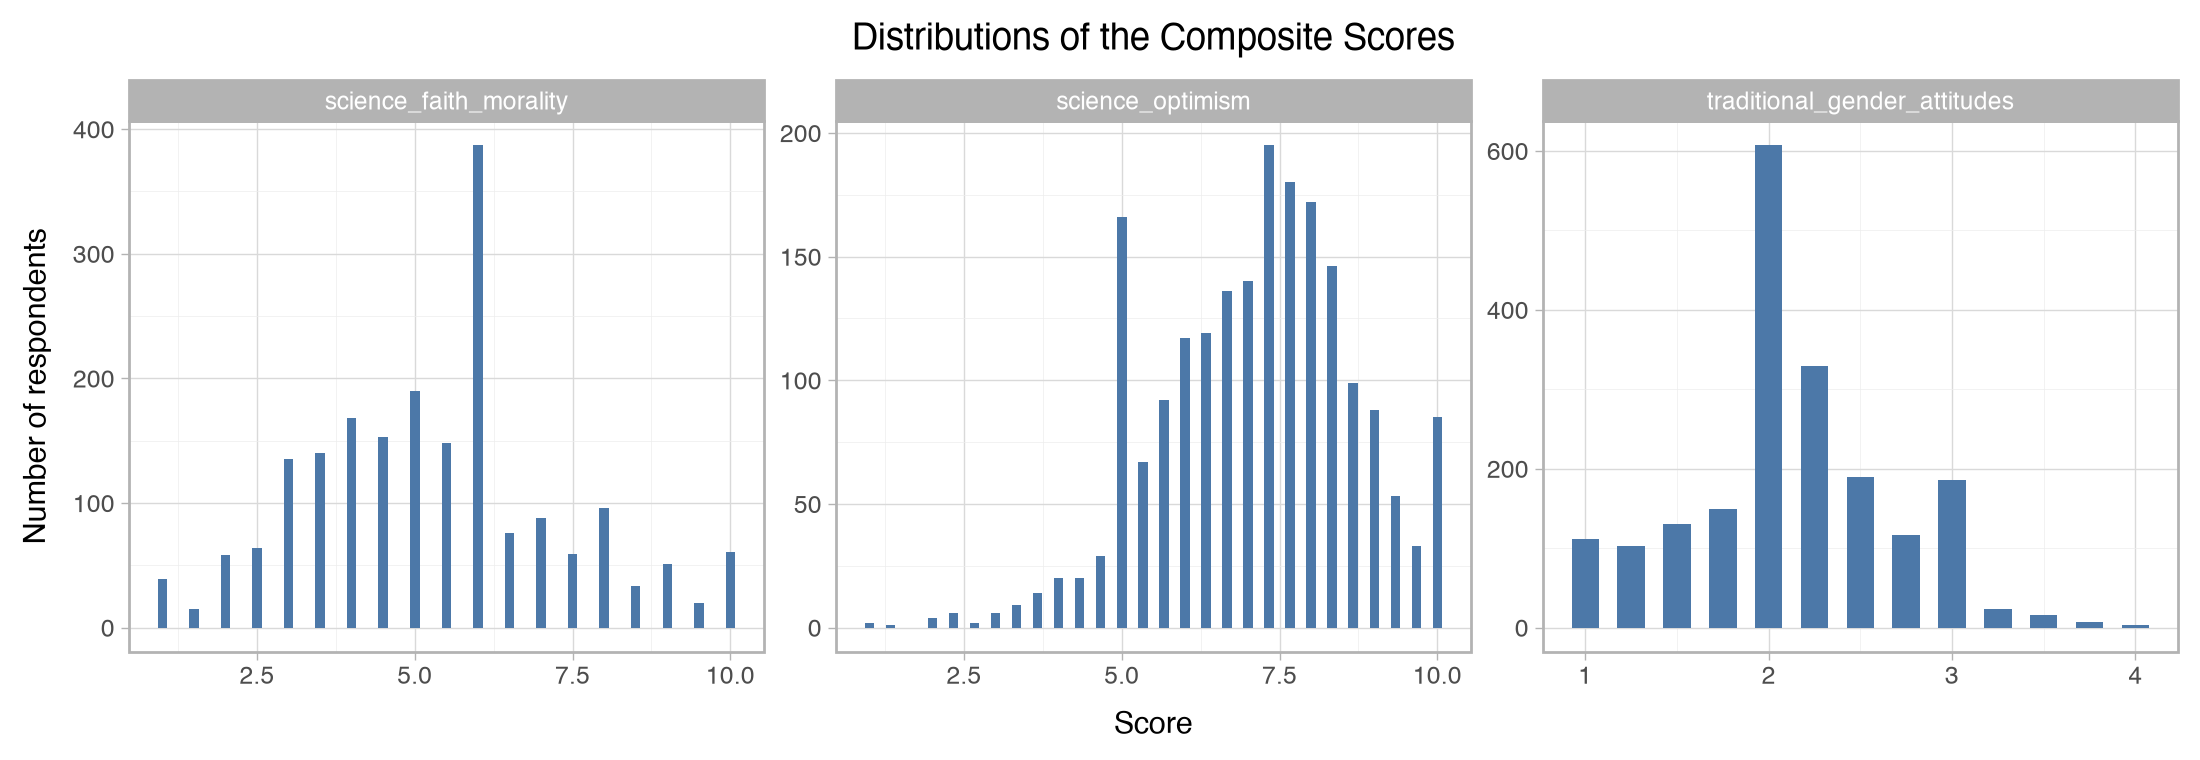

In [23]:
composite_long = df_clean[["traditional_gender_attitudes", "science_optimism", "science_faith_morality"]].melt(  # reshape to long format
    var_name="Composite", value_name="Score").dropna()  # one row per respondent per composite, dropping missing scores

p = (
    ggplot(composite_long, aes(x="Score"))  # one histogram per composite score
    + geom_bar(width=0.15, fill="#4C78A8")  # one bar per possible score value (composites only take certain values)
    + facet_wrap("~Composite", scales="free")  # separate panel for each composite, each with its own axes
    + theme_light()  # clean background, as in class
    + labs(x="Score", y="Number of respondents", title="Distributions of the Composite Scores")  # axis labels and title
    + theme(figure_size=(11, 3.8))  # make the figure wide enough for three panels
)
p.save(OUTPUT_FIGURES / "full_cleaned_composite_distributions.png", dpi=300, verbose=False)  # save the figure
p  # display the figure

### Interpretation

- **Traditional gender-role attitudes:** most scores are clustered around **2** ("disagree" on average), with fewer respondents at the most traditional end (above 3). This matches the mean of 2.12 and confirms that most respondents hold fairly egalitarian views, though there is still a spread of scores.
- **Science optimism:** scores are concentrated between about **5 and 10**, with very few respondents below 4. Most respondents see science as beneficial.
- **Science and faith/morality:** scores are spread across the whole 1–10 range, with a peak around the middle of the scale. Respondents are much more divided on this dimension than on science optimism.

Since the composites are averages of a small number of items, they can only take certain values (for example, the gender score moves in steps of 0.25 and science optimism in steps of one third). Each bar therefore shows one possible score value.

## 9. Saving the Cleaned Dataset

Lastly, we save the cleaned dataset as a new processed file. It contains the original (missing-recoded) items, the reverse-coded items, the recoded `female` variable and the composite scores. The later notebooks (05–10) will load this file.

In [24]:
df_clean.to_csv(NEW_CLEAN_PATH, index=False)  # save the cleaned dataset without the row index

print(f"Cleaned dataset saved to: data/processed/{NEW_CLEAN_PATH.name}")  # confirm where the file was saved
print(f"Number of respondents: {df_clean.shape[0]}")  # number of rows saved
print(f"Number of variables: {df_clean.shape[1]}")  # number of columns saved

Cleaned dataset saved to: data/processed/WVS_Singapore_full_cleaned.csv
Number of respondents: 2012
Number of variables: 44
